# Linear model re-selected on the official metric (shipped model confirmed)

**The question:** the linear model's variant and regressors were selected on the old per-run
TIMSE; only its loss weights were re-tuned for the official metric
(`docs/official_retune.md`). Does a selection scored with the official metric pick something
else?

**The run** (`python -m training.linear_model select`, objective `official`, the default since
this study): the same two-stage selection as before, on the six yearly folds, scored with the
official S_final (`training.competition_score`) against the official truth
(`training.pull_ace_1h`), relative to persistence, as a geometric mean over folds.
- stage 1: 12 variants x 4 ridges, loss weights `official` at blend 0.25 (shortlist regressors);
- stage 2: forward selection over the 117 windowed candidates plus the lead-aligned
  coronal-hole strip `ch_cm_lead_72h`, one per family, stopping below a 0.5% gain;
- then ridge x blend (0.1 / 0.25 / 0.5) on the selected set.

**Decision rule** (as in `official_retune`): a change ships only if it is more than 1% better
than the shipped config and wins at least 4 of 6 folds. The eval year is not used.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import linear_model as tl

EXP = tl.EXPERIMENTS
variants = pd.read_csv(EXP / "linear_model_variants_official.csv")
selection = pd.read_csv(EXP / "linear_model_selection_official.csv")
chosen = json.loads((tl.HERE / "linear_model_config_official.json").read_text(encoding="utf-8"))
shipped = tl.load_config()
pilot = json.loads((tl.HERE / "linear_model_config_official_pilot500_seed0.json")
                   .read_text(encoding="utf-8"))
print("shipped :", shipped.features, f"blend {shipped.blend}, ridge {shipped.ridge}")
print("selected:", tuple(chosen["features"]), f"blend {chosen['blend']}, ridge {chosen['ridge']}")

shipped : ('bt_mean_1h', 'ch_cm_lead_72h', 'xray_peak_max_72h', 'density_mean_24h') blend 0.25, ridge 0.1
selected: ('ch_cm_lead_72h', 'bt_mean_1h', 'xray_peak_max_72h', 'density_mean_1h') blend 0.25, ridge 0.1


## 1. Stage 1: the model variant

In [2]:
cols = ["family", "boxcox", "relative", "ridge", "objective",
        *[f"fold{i}" for i in range(1, 7)]]
with pd.option_context("display.float_format", "{:.4f}".format):
    display(variants[cols].head(10))
best = variants.iloc[0]
same = (best["family"] == shipped.family and best["boxcox"] == shipped.boxcox
        and bool(best["relative"]) == shipped.relative and best["ridge"] == shipped.ridge)
print("best variant equals the shipped variant:", same)

,family,boxcox,relative,ridge,objective,fold1,fold2,fold3,fold4,fold5,fold6
0,gaussian,1.0000,True,0.1000,0.7982,0.7375,0.7024,0.8374,0.9036,0.8733,0.7555
1,gaussian,0.5000,True,0.1000,0.8000,0.7376,0.7028,0.8438,0.9028,0.8720,0.7615
2,gaussian,1.0000,False,0.0000,0.8031,0.7446,0.6964,0.8618,0.9125,0.8786,0.7492
3,gaussian,1.0000,True,0.0000,0.8031,0.7447,0.6964,0.8617,0.9125,0.8786,0.7492
4,inverse_gaussian,1.0000,True,0.1000,0.8039,0.7379,0.7040,0.8500,0.9011,0.8749,0.7750
5,gaussian,0.0000,True,0.1000,0.8040,0.7389,0.7059,0.8514,0.9027,0.8733,0.7715
6,gamma,1.0000,True,0.1000,0.8041,0.7424,0.7054,0.8493,0.9006,0.8732,0.7727
7,gaussian,0.5000,False,0.0000,0.8047,0.7444,0.6954,0.8675,0.9121,0.8775,0.7555
8,gaussian,0.5000,True,0.0000,0.8047,0.7445,0.6954,0.8675,0.9121,0.8775,0.7555
9,gaussian,0.0000,False,0.0000,0.8088,0.7455,0.6973,0.8748,0.9128,0.8794,0.7668


best variant equals the shipped variant: True


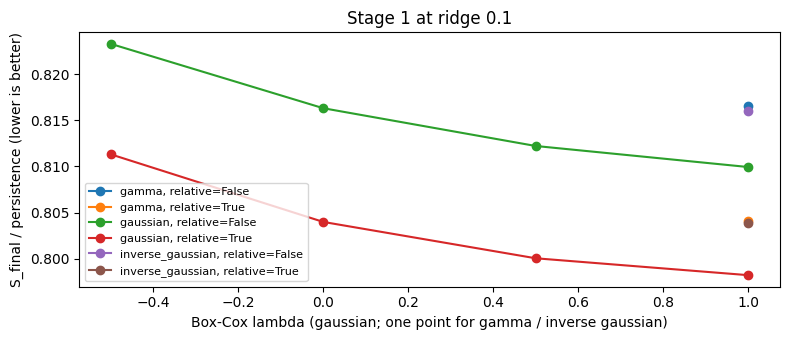

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for (fam, rel), g in variants[variants["ridge"] == 0.1].groupby(["family", "relative"]):
    g = g.sort_values("boxcox")
    ax.plot(g["boxcox"], g["objective"], "o-", label=f"{fam}, relative={rel}")
ax.set_xlabel("Box-Cox lambda (gaussian; one point for gamma / inverse gaussian)")
ax.set_ylabel("S_final / persistence (lower is better)")
ax.set_title("Stage 1 at ridge 0.1")
ax.legend(fontsize=8)
plt.tight_layout()

## 2. Stage 2: forward selection

In [4]:
path = pd.DataFrame(chosen["selection"]["path"])
display(path)
top = (selection.sort_values("objective").groupby("step").head(5)
       .sort_values(["step", "objective"]))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(top)

,step,added,objective,gain
0,0,(speed terms only),0.86306,NaN
1,1,ch_cm_lead_72h,0.82274,0.04672
2,2,bt_mean_1h,0.80105,0.02636
3,3,xray_peak_max_72h,0.79585,0.00649
4,4,density_mean_1h,0.79015,0.00717


,step,candidate,family,window_h,objective
117,1,ch_cm_lead_72h,ch_cm_at,72,0.8227
90,1,ch_cm_at_30h,ch_cm_at,30,0.8267
91,1,ch_cm_at_36h,ch_cm_at,36,0.8277
89,1,ch_cm_at_24h,ch_cm_at,24,0.8281
92,1,ch_cm_at_42h,ch_cm_at,42,0.8315
148,2,bt_mean_1h,bt_mean,1,0.8011
149,2,bt_mean_3h,bt_mean,3,0.8017
187,2,bt_max_6h,bt_max,6,0.8027
150,2,bt_mean_6h,bt_mean,6,0.8036
151,2,bt_mean_12h,bt_mean,12,0.8083


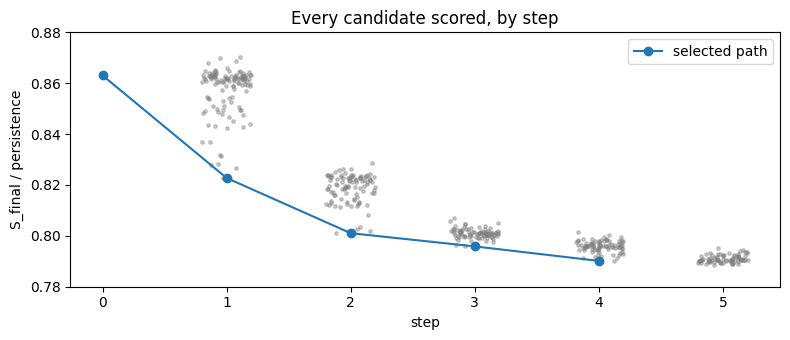

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for step, g in selection.groupby("step"):
    ax.scatter(np.full(len(g), step) + np.random.default_rng(step).uniform(-.2, .2, len(g)),
               g["objective"], s=6, alpha=.4, color="grey")
ax.plot(path["step"], path["objective"], "o-", color="C0", label="selected path")
ax.set_xlabel("step")
ax.set_ylabel("S_final / persistence")
ax.set_ylim(0.78, 0.88)
ax.legend()
ax.set_title("Every candidate scored, by step")
plt.tight_layout()

## 3. The one difference: the density window

Step 4 scores every density window next to the three regressors the shipped model also has, with
the shipped variant, ridge and blend. `density_mean_24h` there **is** the shipped config.

In [6]:
step4 = selection[selection["step"] == 4]
dens = step4[step4["family"] == "density_mean"].sort_values("window_h")
ref4 = float(step4.loc[step4["candidate"] == "density_mean_24h", "objective"].iloc[0])
dens = dens.assign(vs_shipped=100 * (dens["objective"] / ref4 - 1))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(dens[["candidate", "window_h", "objective", "vs_shipped"]])

,candidate,window_h,objective,vs_shipped
310,density_mean_1h,1,0.7901,-0.3055
311,density_mean_3h,3,0.7914,-0.1517
312,density_mean_6h,6,0.7911,-0.1802
313,density_mean_12h,12,0.7922,-0.0437
314,density_mean_24h,24,0.7926,0.0000
315,density_mean_48h,48,0.7926,0.0043


## 4. Per fold: shipped vs selected

Refitted here on all 13,148 training runs, the shipped config and the selected one, each fold
scored with the official S_final relative to persistence. (About two minutes.)

In [7]:
from dataclasses import replace

from training import pull_ace_1h
from training.datasets import load_train

series = load_train()
t0s = tl.training_runs(series)
folds = tl.Folds(series, tl.candidate_table(t0s), series.index.get_indexer(t0s),
                 truth=pull_ace_1h.load())
configs = {
    "speed terms only": replace(shipped, features=()),
    "shipped": shipped,
    "selected": replace(shipped, features=tuple(chosen["features"]),
                        blend=chosen["blend"], ridge=chosen["ridge"]),
}
rows = {name: folds.objective(cfg)[1] for name, cfg in configs.items()}
per_fold = pd.DataFrame(rows, index=[f"{a:%Y-%m}" for a, _ in tl.FOLDS])
per_fold.to_csv(EXP / "official_reselection.csv", float_format="%.6g")


def geo(s):
    return float(np.exp(np.log(s).mean()))


summary = pd.DataFrame({c: {"S/persistence": geo(per_fold[c]),
                            "vs shipped %": 100 * (geo(per_fold[c]) / geo(per_fold["shipped"]) - 1),
                            "folds won": int((per_fold[c] < per_fold["shipped"]).sum())}
                        for c in per_fold}).T
with pd.option_context("display.float_format", "{:.4f}".format):
    display(per_fold)
    display(summary)
gain = -summary.loc["selected", "vs shipped %"]
won = summary.loc["selected", "folds won"]
print(f"selected vs shipped: {gain:.2f}% better, {won} of 6 folds -> "
      f"{'meets' if gain > 1 and won >= 4 else 'does not meet'} the 1% / 4-of-6 rule")

,speed terms only,shipped,selected
2019-10,0.8324,0.7323,0.7326
2020-10,0.7661,0.7027,0.6958
2021-10,0.8924,0.8110,0.8133
2022-10,0.9506,0.8800,0.8776
2023-10,0.9503,0.8663,0.8613
2024-10,0.8038,0.7792,0.7766


,S/persistence,vs shipped %,folds won
speed terms only,0.8631,8.8937,0.0000
shipped,0.7926,0.0000,0.0000
selected,0.7901,-0.3055,4.0000


selected vs shipped: 0.31% better, 4.0 of 6 folds -> does not meet the 1% / 4-of-6 rule


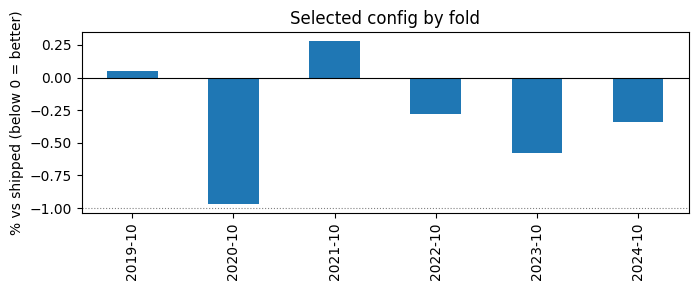

In [8]:
ax = (100 * (per_fold[["selected"]].div(per_fold["shipped"], axis=0) - 1)).plot.bar(
    figsize=(7, 3), legend=False)
ax.axhline(0, color="k", lw=.8)
ax.axhline(-1, color="grey", ls=":", lw=.8)
ax.set_ylabel("% vs shipped (below 0 = better)")
ax.set_title("Selected config by fold")
plt.tight_layout()

## 5. Ridge x blend on the selected set

blend,0.1000,0.2500,0.5000
ridge,,,
0.0000,0.7978,0.7936,0.8103
0.1000,0.7968,0.7901,0.8036
1.0000,0.8458,0.8351,0.8461
10.0000,0.9513,0.9423,0.9562


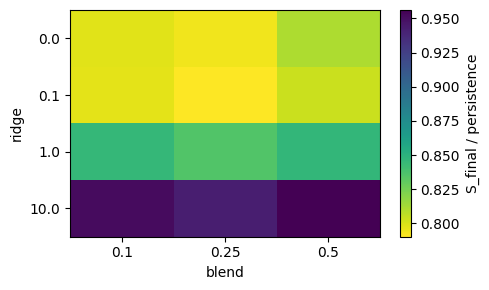

In [9]:
sweep = pd.DataFrame(chosen["selection"]["ridge"]).pivot(
    index="ridge", columns="blend", values="objective")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(sweep)
fig, ax = plt.subplots(figsize=(5, 3))
im = ax.imshow(sweep.to_numpy(), cmap="viridis_r", aspect="auto")
ax.set_xticks(range(sweep.shape[1]), sweep.columns)
ax.set_xlabel("blend")
ax.set_yticks(range(sweep.shape[0]), sweep.index)
ax.set_ylabel("ridge")
plt.colorbar(im, label="S_final / persistence")
plt.tight_layout()

## 6. The 500-run pilot against the full run

In [10]:
print("pilot (500 runs):", [p["added"] for p in pilot["selection"]["path"][1:]],
      f"blend {pilot['blend']}")
print("full (13,148)   :", [p["added"] for p in chosen["selection"]["path"][1:]],
      f"blend {chosen['blend']}")

pilot (500 runs): ['ch_cm_at_30h', 'bt_mean_1h', 'density_mean_48h', 'pressure_mean_24h'] blend 0.5
full (13,148)   : ['ch_cm_lead_72h', 'bt_mean_1h', 'xray_peak_max_72h', 'density_mean_1h'] blend 0.25


## Findings

1. **The official metric re-selects the shipped model.** The best stage-1 variant is the shipped one
   (gaussian, Box-Cox 1, relative to persistence, ridge 0.1), and forward selection adds the same
   four regressor families in the same order: the lead-aligned coronal-hole strip (4.7%),
   `bt_mean_1h` (2.6%), `xray_peak_max_72h` (0.65%) and density (0.72%). Step 5 (`icme_mean_3h`,
   0.20%) stops the search.
2. **The only difference is the density window, 1 h instead of 24 h,** and it is within noise:
   0.31% better, winning 4 of 6 folds (2020-10, 2022-10, 2023-10, 2024-10), against a bar of 1%
   and 4 of 6. The density windows span only 0.7901-0.7926. **The shipped config stays.**
3. **The loss settings are confirmed.** On the selected set, blend 0.25 with ridge 0.1 is best;
   blend 0.5 is 1.7% worse and blend 0.1 0.8% worse; ridge 1 or more is clearly worse.
4. **The regressors are worth 8.2% over the speed terms alone** (0.7926 vs 0.8631), with the
   largest share from the coronal-hole strip, as on the old metric.
5. **The 500-run pilot's choices were noise:** it picked a fixed 30 h coronal-hole image, density
   48 h, pressure and blend 0.5. With about 55 runs per fold it is good for timing only.

**Decision:** no change to the submitted linear model. Selection now uses the official metric by
default (`--objective official`); the old per-run TIMSE stays available as `--objective run_timse`.